# Use Case 2 — Exploratory Analysis & Visualization of Crime

**Objective:** analyse trends and patterns with Pandas, NumPy, Matplotlib and Seaborn.

Input: `output/chicago_crime_clean.pkl` produced by notebook 01.

The interpretations are **computed from the data** (printed under each chart), so they stay
correct when you swap in the real dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

import crime_utils as cu

cu.set_style()
df = pd.read_pickle(cu.CLEAN_CRIME_FILE)
print(f"{len(df):,} crimes | {df['date'].min():%d %b %Y} → {df['date'].max():%d %b %Y}")

498 crimes | 01 Jan 2012 → 04 May 2016


## 1. Crime trend over years

`groupby('year').size()` counts rows per year. **Watch for partial years:** if the data stops in
March, the last year will look like a huge drop. We check how many months each year covers and
flag incomplete ones.

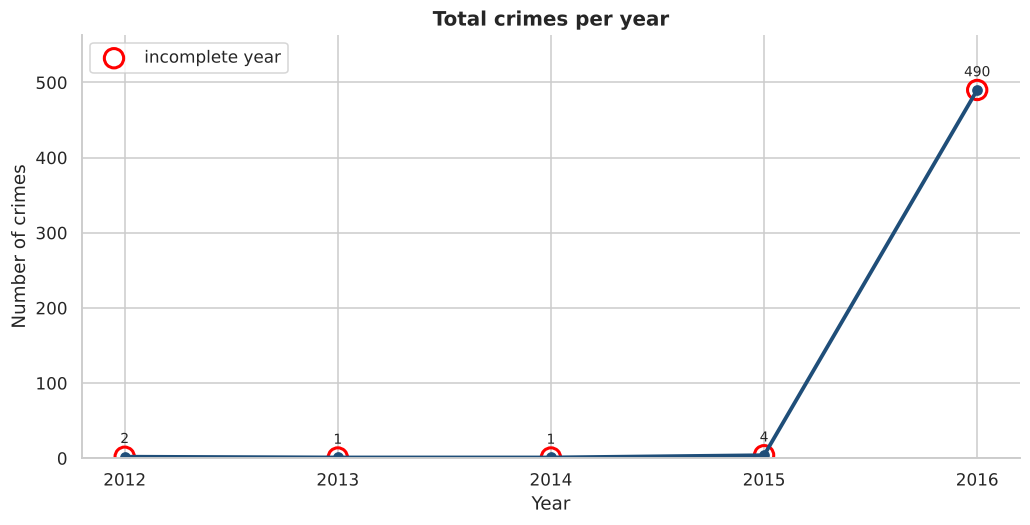

In [2]:
yearly = df.groupby("year").size().rename("crimes")
months_covered = df.groupby("year")["month"].nunique()
partial_years = months_covered[months_covered < 12].index.tolist()

fig, ax = plt.subplots()
ax.plot(yearly.index, yearly.values, marker="o", linewidth=2.5, color="#1f4e79")
for x, y in yearly.items():
    ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
if partial_years:
    ax.scatter(partial_years, yearly[partial_years], s=160, facecolors="none", edgecolors="red",
               linewidths=2, label="incomplete year")
    ax.legend()
ax.set(title="Total crimes per year", xlabel="Year", ylabel="Number of crimes")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xticks(yearly.index)
ax.set_ylim(0, yearly.max() * 1.15)
cu.save_fig(fig, "uc2_01_crimes_per_year")
plt.show()

### Is the crime rate rising or decreasing?
Eyeballing a chart is subjective, so we fit a straight line with `np.polyfit` (degree 1); the
slope = average change in crimes per year.

**But a trend is only meaningful if every year was collected the same way.** Before trusting the
slope we check: (1) are the years complete (12 months)? (2) is one year carrying almost all the
data? If the data fails these checks, the honest answer is *"the trend can't be measured from this
extract"* — the notebook prints that instead of a misleading verdict.

In [3]:
print("Crimes and months covered per year:")
display(pd.DataFrame({"crimes": yearly, "months_covered": months_covered}).T)

slope = np.polyfit(yearly.index, yearly.values, 1)[0] if len(yearly) > 1 else 0.0
top_year_share = yearly.max() / yearly.sum() * 100
full = yearly.drop(partial_years)

if len(full) >= 3 and top_year_share < 50:
    f_slope = np.polyfit(full.index, full.values, 1)[0]
    first, last = full.index.min(), full.index.max()
    change = (full[last] - full[first]) / full[first] * 100
    print(f"Linear trend over complete years: {f_slope:+,.0f} crimes/year → "
          f"{'DECREASING' if f_slope < 0 else 'RISING'}")
    print(f"{first}: {full[first]:,} → {last}: {full[last]:,} ({change:+.1f}%)")
    display(full.pct_change().mul(100).round(1).dropna().to_frame("yoy_%").T)
else:
    print(f"Raw slope: {slope:+.1f} crimes/year — the chart *looks* {'RISING' if slope > 0 else 'DECREASING'}, "
          "but this is NOT a real trend:")
    print(f"  • complete calendar years in the data: {len(full)}")
    print(f"  • {yearly.idxmax()} alone holds {top_year_share:.1f}% of all crimes")
    print("  • every record was last updated in May 2016, so earlier years only contain crimes that "
          "were reported late.")
    print("Verdict: the crime-rate trend over years cannot be determined from this extract. "
          "It needs a full multi-year dataset (same collection rules each year).")

Crimes and months covered per year:


year,2012,2013,2014,2015,2016
crimes,2,1,1,4,490
months_covered,1,1,1,3,5


Raw slope: +97.9 crimes/year — the chart *looks* RISING, but this is NOT a real trend:
  • complete calendar years in the data: 0
  • 2016 alone holds 98.4% of all crimes
  • every record was last updated in May 2016, so earlier years only contain crimes that were reported late.
Verdict: the crime-rate trend over years cannot be determined from this extract. It needs a full multi-year dataset (same collection rules each year).


## 2. Crime distribution by category (`primary_type`)
`value_counts()` gives counts sorted descending; `normalize=True` gives proportions.

In [4]:
cat = pd.DataFrame({
    "count": df["primary_type"].value_counts(),
    "percent": df["primary_type"].value_counts(normalize=True).mul(100).round(2),
})
top10 = cat.head(10)
display(top10.assign(cumulative_percent=top10["percent"].cumsum().round(2)))

,count,percent,cumulative_percent
primary_type,,,
THEFT,105,21.08,21.08
BATTERY,85,17.07,38.15
CRIMINAL DAMAGE,49,9.84,47.99
OTHER OFFENSE,39,7.83,55.82
DECEPTIVE PRACTICE,38,7.63,63.45
ASSAULT,35,7.03,70.48
NARCOTICS,32,6.43,76.91
ROBBERY,30,6.02,82.93
CRIMINAL TRESPASS,17,3.41,86.34


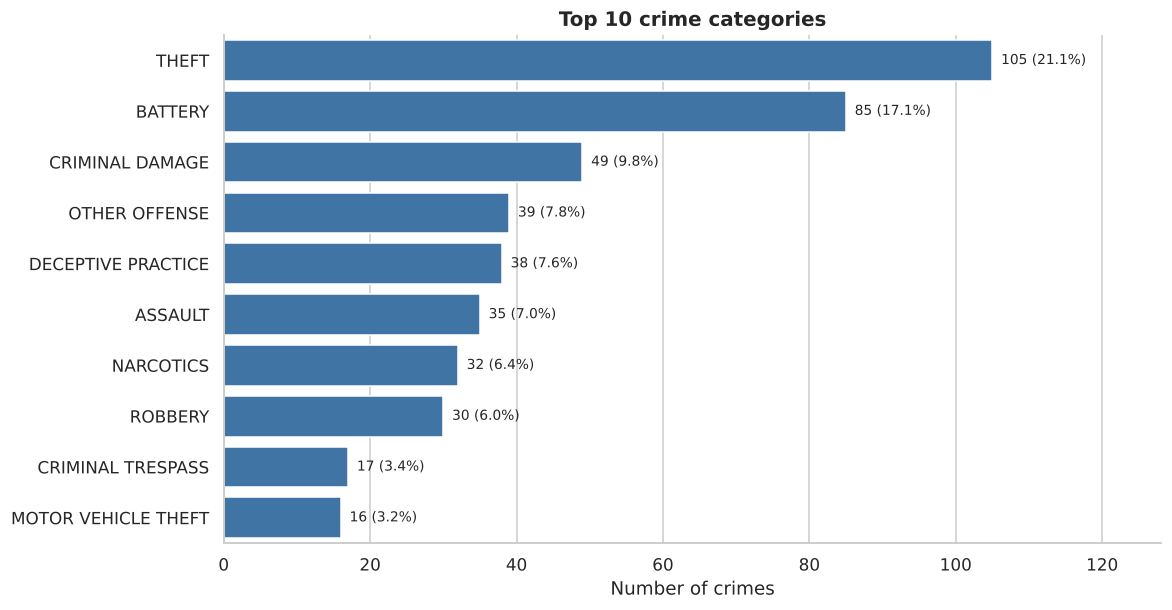

The top 10 categories account for 89.5% of all crimes.


In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=top10["count"], y=top10.index, ax=ax, color="#2e75b6")
for i, (c, p) in enumerate(zip(top10["count"], top10["percent"])):
    ax.text(c, i, f"  {c:,} ({p:.1f}%)", va="center", fontsize=9)
ax.set(title="Top 10 crime categories", xlabel="Number of crimes", ylabel="")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, top10["count"].max() * 1.22)
cu.save_fig(fig, "uc2_02_top10_categories")
plt.show()
print(f"The top 10 categories account for {top10['percent'].sum():.1f}% of all crimes.")

## 3. Arrests and crime outcomes
`arrest` is boolean. The mean of booleans = share of `True`, so `mean() * 100` is the arrest rate.

In [6]:
arrest_rate = df["arrest"].mean() * 100
print(f"Overall arrest rate: {arrest_rate:.2f}%  "
      f"({df['arrest'].sum():,} arrests out of {len(df):,} crimes)")

Overall arrest rate: 24.90%  (124 arrests out of 498 crimes)


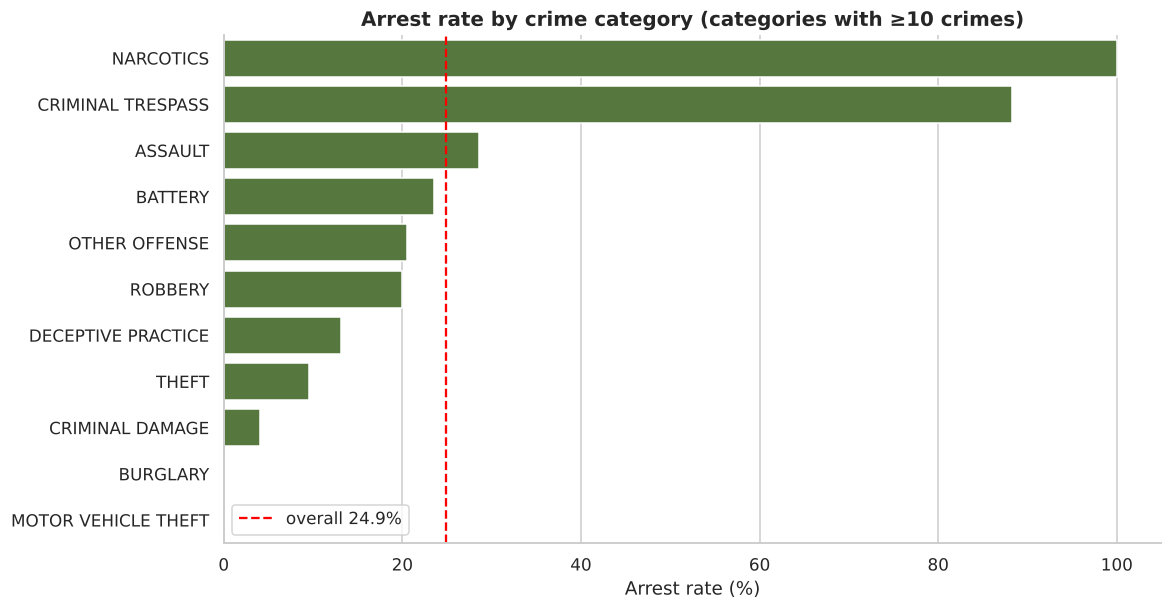

Arrest rate depends heavily on the crime: offences discovered *by* police (e.g. narcotics) almost always end in arrest, while reported property crimes rarely do.


In [7]:
MIN_N = max(10, int(len(df) * 0.01))    # rates from very few crimes are just noise
by_type = (df.groupby("primary_type")["arrest"].agg(crimes="size", arrest_rate="mean")
             .assign(arrest_rate=lambda d: d["arrest_rate"] * 100)
             .query("crimes >= @MIN_N")                      # ignore tiny categories
             .sort_values("arrest_rate", ascending=False))

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=by_type["arrest_rate"], y=by_type.index, ax=ax, color="#548235")
ax.axvline(arrest_rate, color="red", linestyle="--", label=f"overall {arrest_rate:.1f}%")
ax.set(title=f"Arrest rate by crime category (categories with ≥{MIN_N} crimes)", xlabel="Arrest rate (%)", ylabel="")
ax.legend()
cu.save_fig(fig, "uc2_03_arrest_rate_by_category")
plt.show()
print("Arrest rate depends heavily on the crime: offences discovered *by* police (e.g. narcotics) "
      "almost always end in arrest, while reported property crimes rarely do.")

## 4. Heatmap of crime by Month and Day of Week
`pivot_table` reshapes the data to a 12 × 7 grid (months × weekdays). Reindexing the columns
forces Monday→Sunday order (otherwise they're alphabetical).

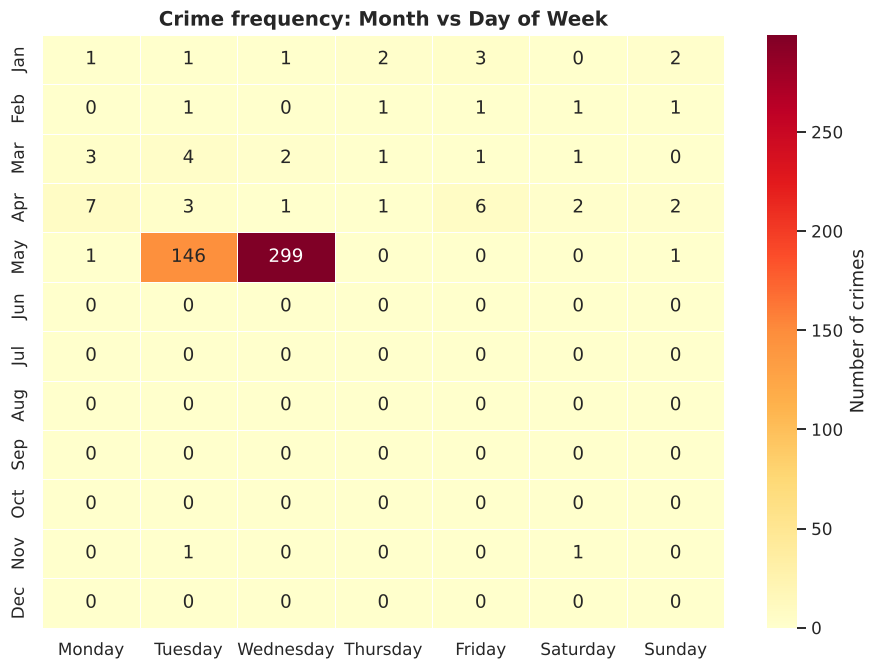

Busiest cell: May / Wednesday (299 crimes)
Busiest weekday overall: Wednesday | quietest: Thursday
⚠ One cell holds 60% of all crimes — the heatmap mostly shows *when the extract was taken* (Tue 3 / Wed 4 May 2016), not a seasonal or weekly crime pattern.


In [8]:
pivot = (df.pivot_table(index="month", columns="day_of_week", values="case_number",
                        aggfunc="count", fill_value=0)
           .reindex(index=range(1, 13), columns=cu.DAY_ORDER, fill_value=0)   # all 12 x 7 cells
           .astype(int))
pivot.index = cu.MONTH_NAMES

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(pivot, annot=True, fmt=",d", cmap="YlOrRd", linewidths=.5,
            cbar_kws={"label": "Number of crimes"}, ax=ax)
ax.set(title="Crime frequency: Month vs Day of Week", xlabel="", ylabel="")
cu.save_fig(fig, "uc2_04_heatmap_month_day")
plt.show()

busiest = pivot.stack().idxmax()
print(f"Busiest cell: {busiest[0]} / {busiest[1]} ({pivot.stack().max():,} crimes)")
print(f"Busiest weekday overall: {pivot.sum().idxmax()} | quietest: {pivot.sum().idxmin()}")
busy_share = pivot.stack().max() / pivot.values.sum() * 100
if busy_share > 30:
    print(f"⚠ One cell holds {busy_share:.0f}% of all crimes — the heatmap mostly shows *when the extract "
          "was taken* (Tue 3 / Wed 4 May 2016), not a seasonal or weekly crime pattern.")

## 5. Top community areas
`community_code` is just a number, so we join the community lookup to show names.
Crimes with an unknown community are excluded from this ranking.

In [9]:
community = pd.read_pickle(cu.OUTPUT_DIR / "community_lookup.pkl")
names = community.set_index("community_code")["community_name"]

top_areas = (df["community_code"].dropna().astype(int).value_counts().head(10)
               .rename_axis("community_code").reset_index(name="crimes"))
top_areas["community_name"] = top_areas["community_code"].map(names).str.title()
top_areas["percent"] = (top_areas["crimes"] / df["community_code"].notna().sum() * 100).round(2)
display(top_areas)

,community_code,crimes,community_name,percent
0,25,34,Austin,6.83
1,8,20,Near North Side,4.02
2,23,20,Humboldt Park,4.02
3,43,16,South Shore,3.21
4,68,16,Englewood,3.21
5,30,16,South Lawndale,3.21
6,32,15,Loop,3.01
7,71,14,Auburn Gresham,2.81
8,6,14,Lake View,2.81
9,49,14,Roseland,2.81


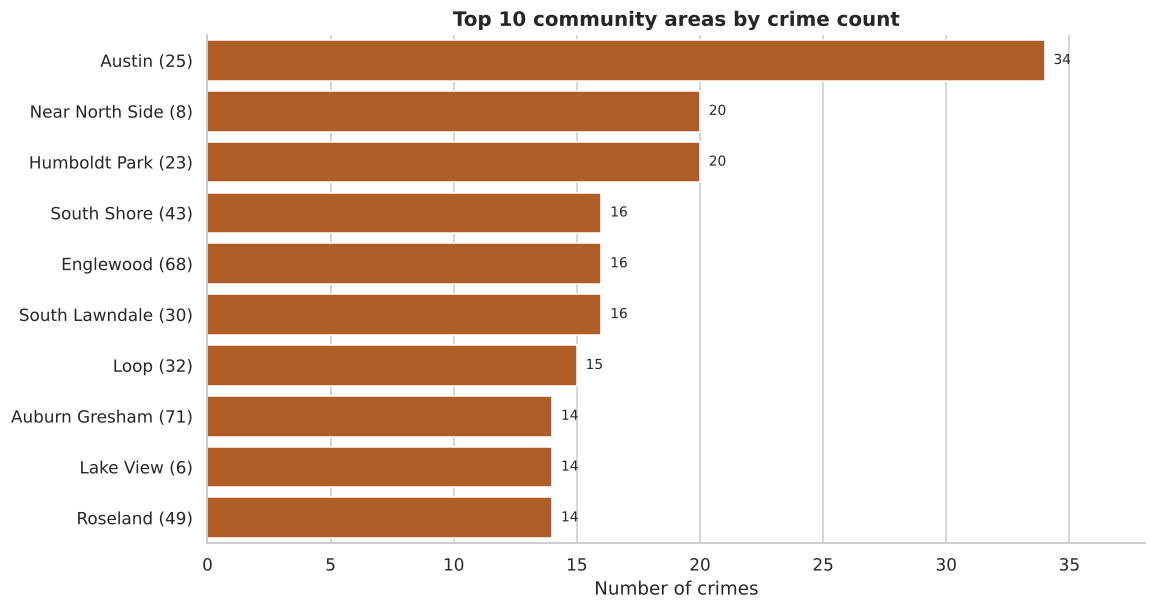

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
labels = top_areas["community_name"] + " (" + top_areas["community_code"].astype(str) + ")"
sns.barplot(x=top_areas["crimes"], y=labels, ax=ax, color="#c55a11")
for i, c in enumerate(top_areas["crimes"]):
    ax.text(c, i, f"  {c:,}", va="center", fontsize=9)
ax.set(title="Top 10 community areas by crime count", xlabel="Number of crimes", ylabel="")
ax.set_xlim(0, top_areas["crimes"].max() * 1.12)
cu.save_fig(fig, "uc2_05_top10_communities")
plt.show()

## Questions
### Q1. Which crime category is most frequent?

In [11]:
print(f"Most frequent: {cat.index[0]} — {cat['count'].iloc[0]:,} crimes ({cat['percent'].iloc[0]:.2f}%)")
print(f"Runner-up:     {cat.index[1]} — {cat['count'].iloc[1]:,} crimes ({cat['percent'].iloc[1]:.2f}%)")

Most frequent: THEFT — 105 crimes (21.08%)
Runner-up:     BATTERY — 85 crimes (17.07%)


### Q2. Is the arrest rate consistent across different years?
We compute the rate per year, plus its **standard deviation** and **range**. A useful rule of
thumb: a range of more than a few percentage points means it is *not* consistent.

year,2012,2013,2014,2015,2016
crimes,2.0,1.0,1.0,4.0,490.00
arrests,2.0,1.0,0.0,2.0,119.00
rate,100.0,100.0,0.0,50.0,24.29


Years with ≥30 crimes (enough for a stable rate): [2016]


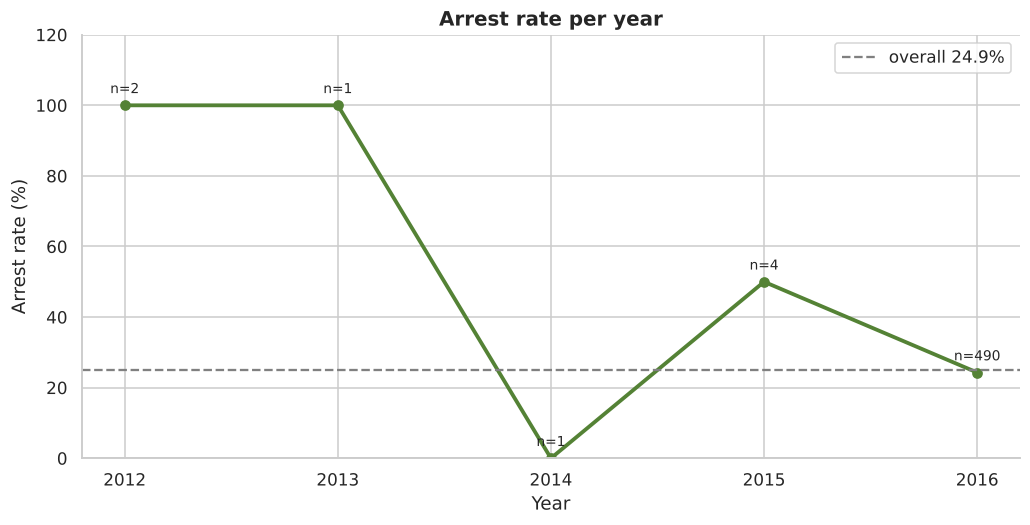

Only 1 year(s) have enough crimes for a reliable rate; the others have 1–4 crimes each, so their rates (2012: 100%, 2013: 100%, 2014: 0%, 2015: 50%) swing between extremes by chance.
Verdict: consistency across years CANNOT be judged from this extract. What we can say: the arrest rate is 24.9% overall, driven mainly by [2016] data.


In [12]:
# a rate needs enough crimes behind it: 1 arrest out of 2 crimes = "50%" means nothing
yr = df.groupby("year")["arrest"].agg(crimes="size", arrests="sum", rate="mean")
yr["rate"] = (yr["rate"] * 100).round(2)
display(yr.T)
reliable = yr[yr["crimes"] >= 30]
arrest_by_year = reliable["rate"]
print(f"Years with ≥30 crimes (enough for a stable rate): {reliable.index.tolist()}")

fig, ax = plt.subplots()
ax.plot(yr.index, yr["rate"], marker="o", linewidth=2.5, color="#548235")
for y_, n_, r_ in zip(yr.index, yr["crimes"], yr["rate"]):
    ax.annotate(f"n={int(n_)}", (y_, r_), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axhline(arrest_rate, color="grey", linestyle="--", label=f"overall {arrest_rate:.1f}%")
ax.set(title="Arrest rate per year", xlabel="Year", ylabel="Arrest rate (%)")
ax.set_xticks(yr.index)
ax.set_ylim(0, max(yr["rate"].max(), 1) * 1.2)
ax.legend()
cu.save_fig(fig, "uc2_06_arrest_rate_per_year")
plt.show()

if len(arrest_by_year) >= 3:
    std, rng = arrest_by_year.std(), arrest_by_year.max() - arrest_by_year.min()
    a_slope = np.polyfit(arrest_by_year.index, arrest_by_year.values, 1)[0]
    verdict = "fairly CONSISTENT" if rng < 3 else "NOT consistent"
    print(f"Std dev: {std:.2f} pts | Range: {rng:.2f} pts | trend {a_slope:+.2f} pts/year "
          f"→ the arrest rate is {verdict} across years.")
else:
    small = yr[yr["crimes"] < 30]
    print(f"Only {len(arrest_by_year)} year(s) have enough crimes for a reliable rate; the others have "
          f"{small['crimes'].min()}–{small['crimes'].max()} crimes each, so their rates "
          f"({', '.join(f'{y}: {r:.0f}%' for y, r in small['rate'].items())}) swing between extremes by chance.")
    print("Verdict: consistency across years CANNOT be judged from this extract. What we can say: "
          f"the arrest rate is {arrest_rate:.1f}% overall, driven mainly by "
          f"{arrest_by_year.index.tolist()} data.")

### Q3. Which month has the highest crime frequency?
Raw monthly totals are biased: February has fewer days, and partial years add extra months. So
we show both the **total** and the **average crimes per day** for each month.

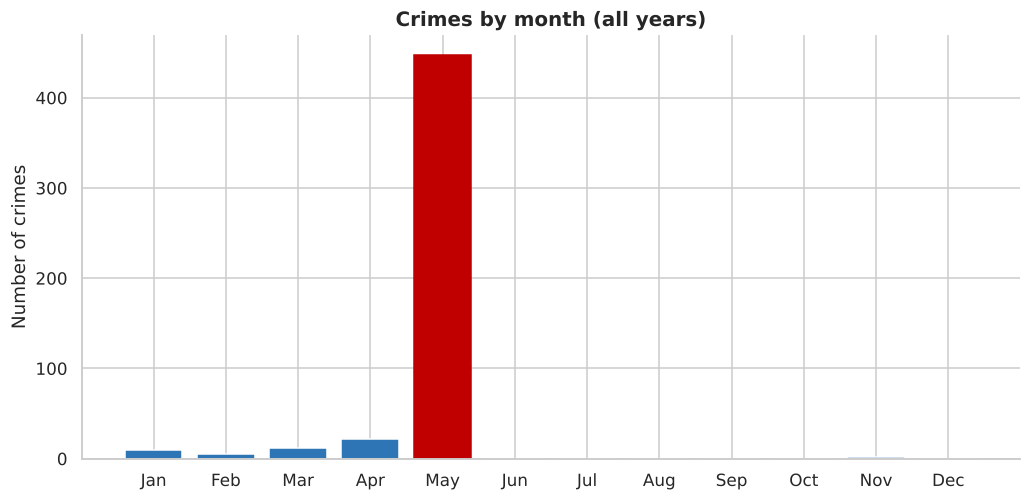

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
crimes,10.0,5.0,12.0,22.0,447.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
crimes_per_day,1.4,1.0,1.2,1.4,74.5,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Highest total: May (447 crimes)
Highest per-day rate: May (74.5 crimes/day)
May holds 89.8% of all crimes.
⚠ This reflects when the extract was taken (early May 2016), not seasonality. With a full year of data, Chicago crime typically peaks in the summer months.


In [13]:
monthly = df.groupby("month").agg(crimes=("case_number", "size")).reindex(range(1, 13), fill_value=0)
days_observed = df.groupby("month")["date"].apply(lambda s: s.dt.normalize().nunique())
monthly["crimes_per_day"] = (monthly["crimes"] / days_observed.reindex(monthly.index)).round(1).fillna(0)
monthly.index = cu.MONTH_NAMES

fig, ax = plt.subplots()
bars = ax.bar(monthly.index, monthly["crimes"], color="#2e75b6")
bars[monthly["crimes"].values.argmax()].set_color("#c00000")
ax.set(title="Crimes by month (all years)", ylabel="Number of crimes")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
cu.save_fig(fig, "uc2_07_crimes_by_month")
plt.show()

display(monthly.T)
print(f"Highest total: {monthly['crimes'].idxmax()} ({monthly['crimes'].max():,} crimes)")
print(f"Highest per-day rate: {monthly['crimes_per_day'].idxmax()} "
      f"({monthly['crimes_per_day'].max()} crimes/day)")
top_m_share = monthly["crimes"].max() / monthly["crimes"].sum() * 100
print(f"{monthly['crimes'].idxmax()} holds {top_m_share:.1f}% of all crimes.")
if top_m_share > 40:
    print("⚠ This reflects when the extract was taken (early May 2016), not seasonality. "
          "With a full year of data, Chicago crime typically peaks in the summer months.")